In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [2]:
df = pd.read_csv("online_retail_II.csv")
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [3]:
print("Shape:", df.shape)
print("Columns:", df.columns)

Shape: (1067371, 8)
Columns: Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='str')


In [4]:
df.describe()

,Quantity,Price,Customer ID
count,1.067371e+06,1.067371e+06,824364.000000
mean,9.938898e+00,4.649388e+00,15324.638504
std,1.727058e+02,1.235531e+02,1697.464450
min,-8.099500e+04,-5.359436e+04,12346.000000
25%,1.000000e+00,1.250000e+00,13975.000000
50%,3.000000e+00,2.100000e+00,15255.000000
75%,1.000000e+01,4.150000e+00,16797.000000
max,8.099500e+04,3.897000e+04,18287.000000


In [5]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [6]:
df = df.dropna(subset=['Customer ID'])

df = df[~df['Invoice'].astype(str).str.startswith('C')]

df = df[(df['Quantity'] > 0) & (df['Price'] > 0)]

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [7]:
print("Shape after cleaning:", df.shape)
df.head()

Shape after cleaning: (805549, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [8]:
df['Amount'] = df['Quantity'] * df['Price']

df[['Quantity', 'Price', 'Amount']].head()

,Quantity,Price,Amount
0,12,6.95,83.4
1,12,6.75,81.0
2,12,6.75,81.0
3,48,2.10,100.8
4,24,1.25,30.0


In [9]:
date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('Customer ID').agg(
    Recency=('InvoiceDate', lambda x: (date - x.max()).days),
    Frequency=('Invoice', 'nunique'),
    Monetary=('Amount', 'sum')
)



In [10]:
print(rfm.shape)
rfm.describe()

(5878, 3)


,Recency,Frequency,Monetary
count,5878.000000,5878.000000,5878.000000
mean,201.331916,6.289384,3018.616737
std,209.338707,13.009406,14737.731040
min,1.000000,1.000000,2.950000
25%,26.000000,1.000000,348.762500
50%,96.000000,3.000000,898.915000
75%,380.000000,7.000000,2307.090000
max,739.000000,398.000000,608821.650000


In [11]:
scaler = StandardScaler()
X = scaler.fit_transform(rfm)

print(X[:5])

[[ 0.59558355  0.43899789  5.05805027]
 [-0.95227909  0.13150188  0.17743068]
 [-0.60353226 -0.09912012 -0.06780567]
 [-0.87106408 -0.17599412  0.09568591]
 [ 0.51914589 -0.40661612 -0.18214779]]


In [12]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

rfm['KMeans'] = kmeans.fit_predict(X)



In [13]:
dbscan = DBSCAN(eps=0.5, min_samples=5)

rfm['DBSCAN'] = dbscan.fit_predict(X)

rfm['DBSCAN'].value_counts()

DBSCAN
 0    5813
-1      65
Name: count, dtype: int64

In [14]:
pca = PCA(n_components=2)

pca_data = pca.fit_transform(X)

print(pca.explained_variance_ratio_)

[0.57679861 0.304666  ]


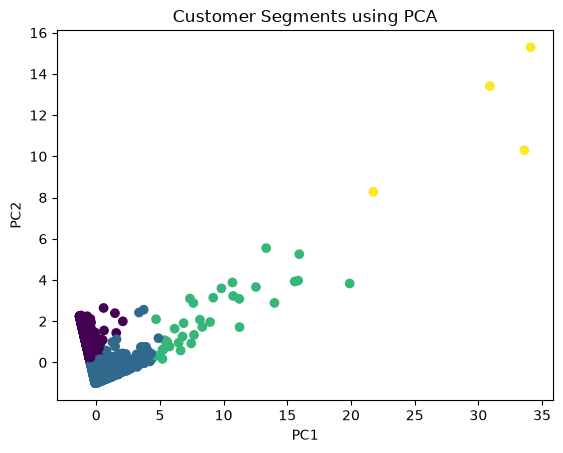

In [16]:
plt.scatter(pca_data[:,0], pca_data[:,1], c=rfm['KMeans'])

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Customer Segments using PCA")

plt.show()

In [15]:
tsne = TSNE(n_components=2, random_state=42)

tsne_data = tsne.fit_transform(X)

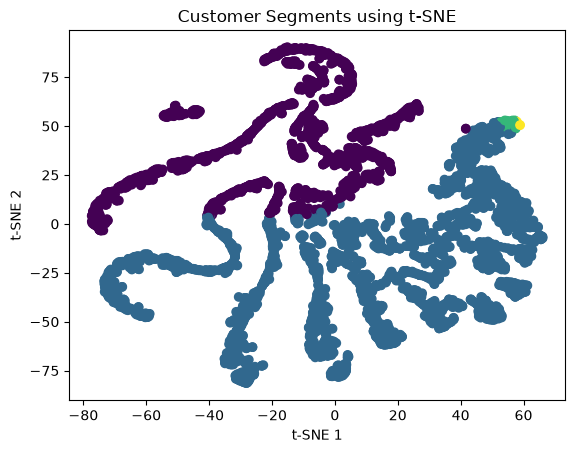

In [17]:
plt.scatter(tsne_data[:,0], tsne_data[:,1], c=rfm['KMeans'])

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("Customer Segments using t-SNE")

plt.show()

In [18]:
summary = rfm.groupby('KMeans')[['Recency', 'Frequency', 'Monetary']].mean()
summary

,Recency,Frequency,Monetary
KMeans,,,
0,463.032032,2.212212,765.244446
1,67.005728,7.307732,3009.402451
2,25.942857,103.714286,83086.079771
3,3.500000,212.500000,436835.792500
